In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sbs

In [15]:
column_names = [
    "state", "county", "community", "communityname", "fold", 
    "population", "householdsize", "racepctblack", "racePctWhite", 
    "racePctAsian", "racePctHisp", "agePct12t21", "agePct12t29", 
    "agePct16t24", "agePct65up", "numbUrban", "pctUrban", "medIncome", 
    "pctWWage", "pctWFarmSelf", "pctWInvInc", "pctWSocSec", "pctWPubAsst", 
    "pctWRetire", "medFamInc", "perCapInc", "whitePerCap", "blackPerCap", 
    "indianPerCap", "AsianPerCap", "OtherPerCap", "HispPerCap", 
    "NumUnderPov", "PctPopUnderPov", "PctLess9thGrade", "PctNotHSGrad", 
    "PctBSorMore", "PctUnemployed", "PctEmploy", "PctEmplManu", 
    "PctEmplProfServ", "PctOccupManu", "PctOccupMgmtProf", "MalePctDivorce", 
    "MalePctNevMarr", "FemalePctDiv", "TotalPctDiv", "PersPerFam", 
    "PctFam2Par", "PctKids2Par", "PctYoungKids2Par", "PctTeen2Par", 
    "PctWorkMomYoungKids", "PctWorkMom", "NumIlleg", "PctIlleg", 
    "NumImmig", "PctImmigRecent", "PctImmigRec5", "PctImmigRec8", 
    "PctImmigRec10", "PctRecentImmig", "PctRecImmig5", "PctRecImmig8", 
    "PctRecImmig10", "PctSpeakEnglOnly", "PctNotSpeakEnglWell", 
    "PctLargHouseFam", "PctLargHouseOccup", "PersPerOccupHous", 
    "PersPerOwnOccHous", "PersPerRentOccHous", "PctPersOwnOccup", 
    "PctPersDenseHous", "PctHousLess3BR", "MedNumBR", "HousVacant", 
    "PctHousOccup", "PctHousOwnOcc", "PctVacantBoarded", "PctVacMore6Mos", 
    "MedYrHousBuilt", "PctHousNoPhone", "PctWOFullPlumb", "OwnOccLowQuart", 
    "OwnOccMedVal", "OwnOccHiQuart", "RentLowQ", "RentMedian", "RentHighQ", 
    "MedRent", "MedRentPctHousInc", "MedOwnCostPctInc", 
    "MedOwnCostPctIncNoMtg", "NumInShelters", "NumStreet", "PctForeignBorn", 
    "PctBornSameState", "PctSameHouse85", "PctSameCity85", "PctSameState85", 
    "LemasSwornFT", "LemasSwFTPerPop", "LemasSwFTFieldOps", 
    "LemasSwFTFieldPerPop", "LemasTotalReq", "LemasTotReqPerPop", 
    "PolicReqPerOffic", "PolicPerPop", "RacialMatchCommPol", "PctPolicWhite", 
    "PctPolicBlack", "PctPolicHisp", "PctPolicAsian", "PctPolicMinor", 
    "OfficAssgnDrugUnits", "NumKindsDrugsSeiz", "PolicAveOTWorked", 
    "LandArea", "PopDens", "PctUsePubTrans", "PolicCars", "PolicOperBudg", 
    "LemasPctPolicOnPatr", "LemasGangUnitDeploy", "LemasPctOfficDrugUn", 
    "PolicBudgPerPop", "ViolentCrimesPerPop"
]

ds = pd.read_csv("communities.data", sep=",", header=None, na_values=['?'], names=column_names)
ds = ds.drop(columns=['state', 'county', 'community', 'communityname', 'fold'])
print(ds.head())

   population  householdsize  racepctblack  racePctWhite  racePctAsian  \
0        0.19           0.33          0.02          0.90          0.12   
1        0.00           0.16          0.12          0.74          0.45   
2        0.00           0.42          0.49          0.56          0.17   
3        0.04           0.77          1.00          0.08          0.12   
4        0.01           0.55          0.02          0.95          0.09   

   racePctHisp  agePct12t21  agePct12t29  agePct16t24  agePct65up  ...  \
0         0.17         0.34         0.47         0.29        0.32  ...   
1         0.07         0.26         0.59         0.35        0.27  ...   
2         0.04         0.39         0.47         0.28        0.32  ...   
3         0.10         0.51         0.50         0.34        0.21  ...   
4         0.05         0.38         0.38         0.23        0.36  ...   

   LandArea  PopDens  PctUsePubTrans  PolicCars  PolicOperBudg  \
0      0.12     0.26            0.20       0

In [16]:
def prepare_data(ds, target):        
    X = ds.drop(columns=target).copy()
    y = ds[target].values
    return X, y   


X, y = prepare_data(ds, target='ViolentCrimesPerPop')

In [17]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')

X_clean = imputer.fit_transform(X)
y_clean = imputer.fit_transform(y.reshape(-1, 1)).flatten()

In [18]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.25, random_state=0)

In [19]:
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()

X_train_scaled = sc_X.fit_transform(X_train)
X_test_scaled = sc_X.transform(X_test)

# For SVR
# sc_y = StandardScaler()
# y_train_scaled = sc_y.fit_transform(y_train.reshape(-1, 1)).flatten()

In [20]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression(n_jobs=-1)
lin_reg.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,-1
,positive,False


In [21]:
from sklearn.metrics import mean_squared_error, r2_score

y_pred = lin_reg.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")

Mean Squared Error: 0.02
R² Score: 0.64


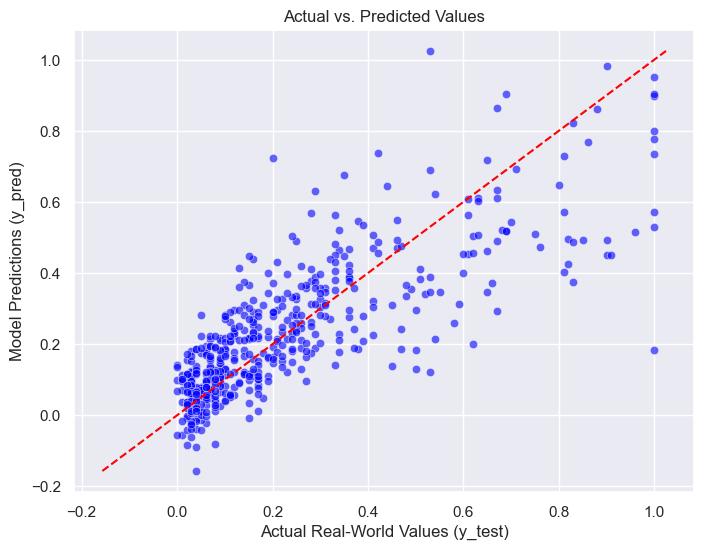

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make the canvas look modern and set its size
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 6))

# Create the histogram using Seaborn
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color="blue")
# sns.histplot(x=y_test, y=y_pred, bins=50, pmax=0.9, cmap="Blues", cbar=True)
# Draw the perfect prediction diagonal line (using Matplotlib)
# We draw a red dashed line from the minimum value to the maximum value
min_val = min(min(y_test), min(y_pred))
max_val = max(max(y_test), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.title("Actual vs. Predicted Values")
plt.xlabel("Actual Real-World Values (y_test)")
plt.ylabel("Model Predictions (y_pred)")
plt.show()

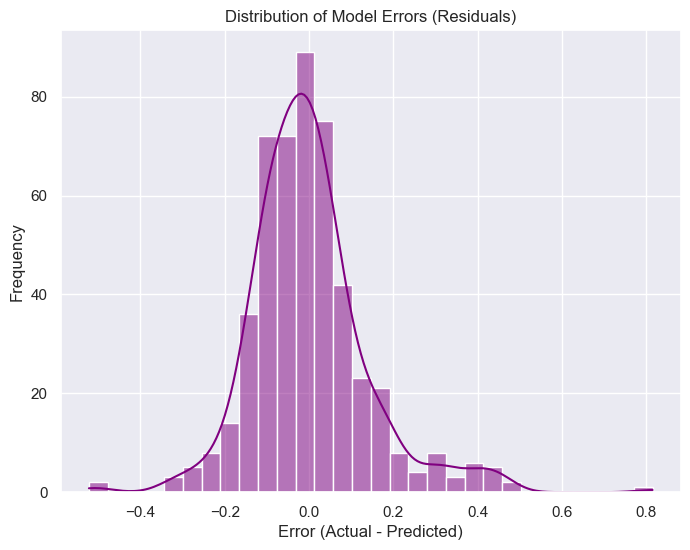

In [29]:
# Calculate the errors
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

sns.histplot(residuals, kde=True, color="purple", bins=30)

plt.title("Distribution of Model Errors (Residuals)")
plt.xlabel("Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.show()

In [36]:
from sklearn.preprocessing import PolynomialFeatures
poly_reg = PolynomialFeatures(degree=2)
X_poly = poly_reg.fit_transform(X_train_scaled)
lin_reg_2 = LinearRegression()
lin_reg_2.fit(X_poly, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [37]:
from sklearn.metrics import mean_squared_error, r2_score

X_test_poly = poly_reg.transform(X_test_scaled)
y_pred_poly = lin_reg_2.predict(X_test_poly)

mse = mean_squared_error(y_test, y_pred_poly)
r2 = r2_score(y_test, y_pred_poly)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")

Mean Squared Error: 0.14
R² Score: -1.60


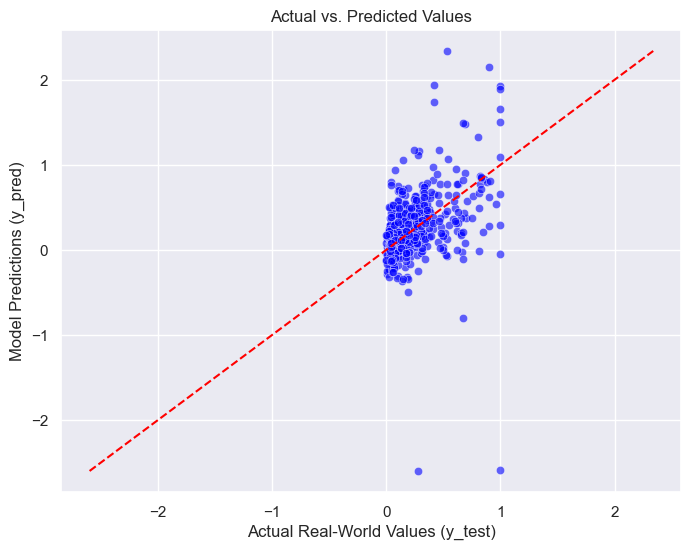

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make the canvas look modern and set its size
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 6))

# Create the histogram using Seaborn
sns.scatterplot(x=y_test, y=y_pred_poly, alpha=0.6, color="blue")
# sns.histplot(x=y_test, y=y_pred_poly, bins=50, pmax=0.9, cmap="Blues", cbar=True)
# Draw the perfect prediction diagonal line (using Matplotlib)
# We draw a red dashed line from the minimum value to the maximum value
min_val = min(min(y_test), min(y_pred_poly))
max_val = max(max(y_test), max(y_pred_poly))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.title("Actual vs. Predicted Values")
plt.xlabel("Actual Real-World Values (y_test)")
plt.ylabel("Model Predictions (y_pred)")
plt.show()

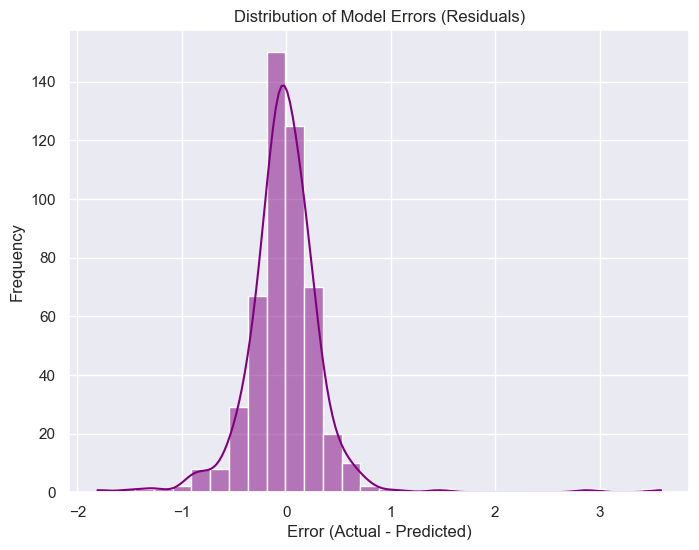

In [39]:
# Calculate the errors
residuals = y_test - y_pred_poly

plt.figure(figsize=(8, 6))

sns.histplot(residuals, kde=True, color="purple", bins=30)

plt.title("Distribution of Model Errors (Residuals)")
plt.xlabel("Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.show()

In [6]:
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()

X_train_scaled = sc_X.fit_transform(X_train)
X_test_scaled = sc_X.transform(X_test)

# For SVR
sc_y = StandardScaler()
y_train_scaled = sc_y.fit_transform(y_train.reshape(-1, 1)).flatten()

In [8]:
from sklearn.svm import SVR
svr = SVR(kernel='rbf')
svr.fit(X_train_scaled, y_train_scaled)
y_pred_scaled = svr.predict(X_test_scaled)
y_pred = sc_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1))

[[ 0.09757122  0.45      ]
 [ 0.13124595  0.06      ]
 [ 0.17324498  0.26      ]
 [ 0.06325172  0.09      ]
 [ 0.21245879  0.33      ]
 [ 0.22772555  0.16      ]
 [ 0.4025952   0.23      ]
 [ 0.22184636  0.17      ]
 [ 0.29302112  0.14      ]
 [ 0.117109    0.15      ]
 [ 0.09234498  0.04      ]
 [ 0.54478836  0.62      ]
 [ 0.08288405  0.05      ]
 [ 0.04563777  0.09      ]
 [ 0.3840654   0.28      ]
 [ 0.21507975  0.12      ]
 [ 0.19586436  0.22      ]
 [ 0.1662139   0.2       ]
 [ 0.35097185  0.27      ]
 [ 0.37064437  0.53      ]
 [ 0.0986358   0.08      ]
 [ 0.67419675  0.71      ]
 [ 0.06467324  0.21      ]
 [ 0.53585756  0.69      ]
 [ 0.12650959  0.        ]
 [ 0.32506932  0.24      ]
 [ 0.23772806  0.5       ]
 [ 0.0976939   0.2       ]
 [ 0.08644929  0.03      ]
 [ 0.37661502  0.41      ]
 [ 0.18776088  0.1       ]
 [ 0.2594731   0.18      ]
 [ 0.21699386  0.29      ]
 [ 0.07021491  0.05      ]
 [ 0.2747974   0.16      ]
 [ 0.43094568  0.35      ]
 [ 0.34705626  0.66      ]
 

In [10]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")

Mean Squared Error: 0.02
R² Score: 0.62


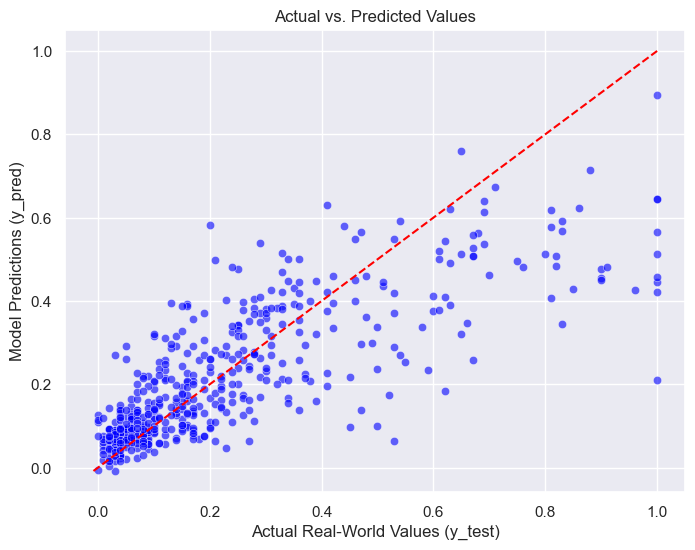

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make the canvas look modern and set its size
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 6))

# Create the histogram using Seaborn
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color="blue")
# Draw the perfect prediction diagonal line (using Matplotlib)
# We draw a red dashed line from the minimum value to the maximum value
min_val = min(min(y_test), min(y_pred))
max_val = max(max(y_test), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.title("Actual vs. Predicted Values")
plt.xlabel("Actual Real-World Values (y_test)")
plt.ylabel("Model Predictions (y_pred)")
plt.show()

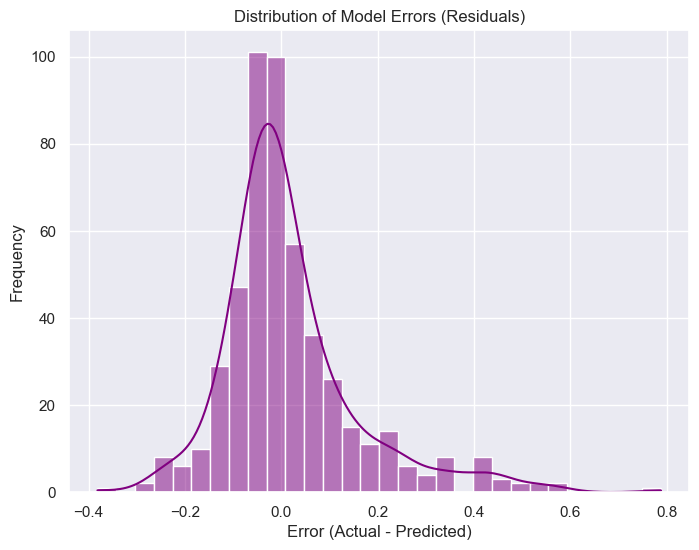

In [12]:
# Calculate the errors
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

sns.histplot(residuals, kde=True, color="purple", bins=30)

plt.title("Distribution of Model Errors (Residuals)")
plt.xlabel("Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.show()